# Feature extraction

Bộ tìm kiếm của câu lạc bộ đã nạp được model. Bây giờ có hai yêu cầu: tìm ảnh gần giống một ảnh truy vấn và phân loại một số ảnh đã được gán nhãn. Nếu mỗi lần thay bộ phân loại lại huấn luyện cả mạng, ta mất nhiều thời gian. Có thể để model làm bộ đọc cố định, biến mỗi ảnh thành một vector, rồi dùng lại các thuật toán quen thuộc ở chương 2 không? Đó là feature extraction: giữ một encoder, lấy biểu diễn của dữ liệu và giải bài toán trên những biểu diễn ấy.

> **Mục tiêu sau bài này**
>
> - Giải thích encoder, embedding, pooling và linear probe làm những việc khác nhau.
> - Trích đặc trưng một lần rồi dùng logistic regression, kNN và tìm kiếm tương đồng.
> - Tính cosine similarity bằng tay, kiểm padding mask và shape khi pooling.
> - Chặn rò rỉ dữ liệu khi học tiền xử lý, chọn encoder và lưu embedding.

## Vì sao cần một biểu diễn khác?

Hai ảnh cùng chiếc bàn có thể lệch vị trí vài pixel. Khoảng cách giữa hai mảng pixel lúc ấy lớn, dù ta coi chúng cùng nội dung. Tương tự, “tìm đường ngắn nhất” và “shortest path” không có nhiều ký tự chung, nhưng gần nhau về chủ đề. Ta muốn biểu diễn giữ những khác biệt có ích và giảm những khác biệt ít liên quan.

Encoder là một hàm $f_\theta$ nhận đầu vào $\mathbf{x}$ và trả về vector $\mathbf{z}$ có $d$ thành phần:

$$\mathbf{z}=f_\theta(\mathbf{x})\in\mathbb{R}^d.$$

$\theta$ là trọng số encoder. Feature extraction giữ $\theta$ cố định. Embedding là tên thường dùng cho vector biểu diễn này; một số tài liệu gọi chung là feature. Không có quy định rằng tọa độ thứ 7 phải nghĩa là “có bàn”. Các tọa độ cùng nhau tạo ra hình học; việc gần xa có ích đến đâu còn phụ thuộc mục tiêu mà encoder đã học.



Model có head phân loại trả về logits của nhãn cũ. Để lấy đặc trưng, ta thường dùng biểu diễn trước head hoặc API feature của model. Logits cũng là một biểu diễn, nhưng bị buộc vào các nhãn cũ và không mặc nhiên là lựa chọn tốt nhất. Với model có nhiều token, cần một quy tắc pooling để gộp các vector token thành một vector cho cả mẫu. Quy tắc ấy là một phần của thí nghiệm, phải ghi lại. Với ResNet-50 của torchvision, thay `model.fc = torch.nn.Identity()` rồi gọi `features = model(x)` là được vector 2048 chiều trước head.

Trước học sâu, người ta tự thiết kế đặc trưng như tỉ lệ màu, cạnh, kết cấu; encoder học sâu tự học chúng từ dữ liệu. Có encoder tốt, nhiều việc chỉ còn là so vector: tìm sản phẩm giống ảnh chụp đôi giày là tìm embedding gần nhất trong kho; mở khóa bằng khuôn mặt với đúng một ảnh đăng ký là so embedding ảnh mới với embedding đã lưu theo một ngưỡng. Khi mỗi lớp chỉ có vài ảnh, lấy trung bình embedding của chúng thành một tâm (prototype) cho mỗi lớp rồi gán ảnh mới vào tâm gần nhất.

**Hỏi nhanh.** Encoder cho mỗi ảnh một vector 512 số, và có 100 ảnh. Ma trận embedding xếp mỗi mẫu một hàng có shape gì?

- A. `(512, 100)`
- B. `(100, 512)`
- C. `(100,)`
- D. `(1, 51200)`

<details><summary>Đáp án</summary>

B. `(100, 512)`

Mỗi ảnh một hàng, mỗi tọa độ một cột, nên kNN, logistic regression hay KMeans của scikit-learn nhận thẳng ma trận này. `(512, 100)` là bản chuyển vị, thư viện sẽ hiểu thành 512 mẫu, mỗi mẫu 100 đặc trưng. `(100,)` chỉ còn một số cho mỗi ảnh. `(1, 51200)` trải cả kho thành một mẫu duy nhất.

</details>

**Hỏi nhanh.** ResNet-50 học trên ImageNet có head trả về 1000 logits, và ngay trước head là một vector 2048 số. Câu lạc bộ cần phân loại ảnh thành 5 loại linh kiện máy tính, không loại nào trùng tên lớp ImageNet. Nên lấy đặc trưng nào cho linear probe?

- A. 1000 logits, vì đó là tầng có ý nghĩa rõ nhất
- B. Xác suất softmax của 1000 lớp, vì đã chuẩn hóa tổng bằng 1
- C. Vector 2048 số trước head, rồi học một head 5 lớp mới
- D. Pixel thô, vì nhãn mới không có trong ImageNet

<details><summary>Đáp án</summary>

C. Vector 2048 số trước head, rồi học một head 5 lớp mới

Vector trước head chứa các đặc trưng chung mà head cũ dùng để chấm điểm, còn head mới học cách đọc chúng cho 5 nhãn mới. Logits đã bị nén vào câu hỏi “giống lớp ImageNet nào”. Softmax lại ép phần lớn giá trị về gần 0 khi có một lớp áp đảo. Nhãn mới không có trong ImageNet không làm đặc trưng thành vô dụng: cạnh, vân và hình dạng vẫn dùng lại được. Có ích tới mức nào thì validation trả lời.

</details>

## Thử offline: encoder học từ dữ liệu train

Để mọi bước chạy trên CPU trong vài giây, bài dùng `load_digits` có sẵn trong scikit-learn: ảnh chữ số $8\times8$, mỗi ảnh trải thành 64 pixel. Encoder là PCA giảm còn 16 tọa độ. Nó được học một lần trên tập train rồi đứng yên, đúng vai trò của một model pretrained, chỉ khác là nhỏ và học ngay tại chỗ thay vì tải về. Các bước phía sau (chia dữ liệu, trích, học head, tìm kiếm, phân cụm) giữ nguyên khi thay PCA bằng một CNN hay Transformer; [recipe của chương](recipes/README.md) đi đúng quy trình ấy với DistilBERT cho văn bản, trên dữ liệu và asset người dùng chuẩn bị.

Chia dữ liệu trước khi học PCA. PCA không dùng nhãn, nhưng học các hướng biến thiên từ input; nếu cho nó nhìn validation thì validation đã góp vào cách biểu diễn. Trong bài, tập giữ lại gọi là validation vì ta dùng nó đọc và so sánh cách làm. Không báo nó như một test cuối độc lập sau khi đã thử nhiều phương án.

In [ ]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

digits = load_digits()
indices = np.arange(len(digits.target))
train_id, valid_id = train_test_split(
    indices, test_size=0.3, random_state=7, stratify=digits.target
)
X_train = digits.data[train_id] / 16.0
X_valid = digits.data[valid_id] / 16.0
y_train = digits.target[train_id]
y_valid = digits.target[valid_id]

encoder = PCA(n_components=16, svd_solver="full")
Z_train = encoder.fit_transform(X_train)
Z_valid = encoder.transform(X_valid)
print("pixel:", X_train.shape, X_valid.shape)
print("embedding:", Z_train.shape, Z_valid.shape)
print("id tach roi:", len(set(train_id) & set(valid_id)) == 0)

pixel: (1257, 64) (540, 64)
embedding: (1257, 16) (540, 16)
id tach roi: True


Dòng cuối kiểm rằng không ID nào nằm ở cả hai tập. Điều đó chưa đủ để nói hai tập độc lập: `load_digits` không kèm thông tin người viết, nên chữ của cùng một người có thể nằm ở cả hai phía. Với kho ảnh câu lạc bộ, nhiều ảnh chụp liên tiếp trong một buổi hoạt động gần như trùng nhau; nếu mục tiêu là dự đoán cho một buổi mới thì phải chia theo buổi hoặc theo nguồn.



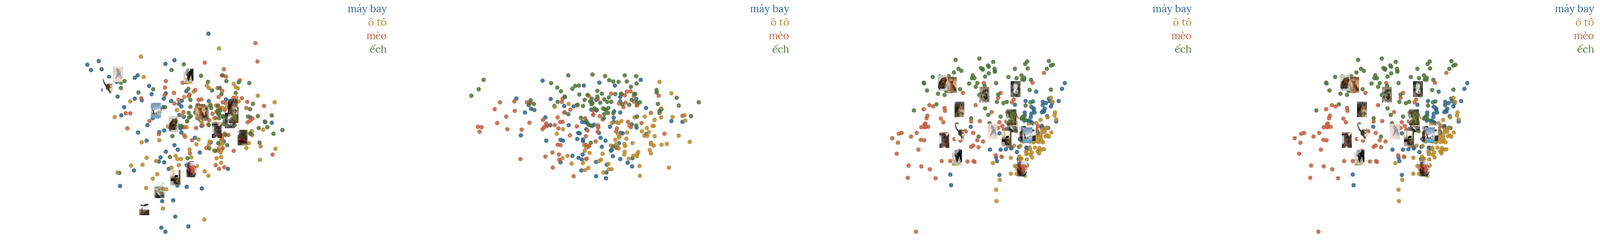

Ma trận $Z$ được tạo một lần. Khi dùng encoder neural thật, ta đặt encoder ở `eval()` và tắt gradient, chạy theo batch, lưu `id` cùng embedding. Nếu đầu vào có augmentation ngẫu nhiên, embedding cũng ngẫu nhiên; cần chọn rõ một phép biến đổi cố định, hoặc một tập biến đổi cố định rồi lấy trung bình, và kiểm cách đó trên validation.

**Hỏi nhanh.** Kho ảnh câu lạc bộ có 40 buổi hoạt động, mỗi buổi khoảng 50 ảnh chụp liên tiếp. Chia ngẫu nhiên theo từng ảnh thì kNN trên embedding đạt 0.99 trên validation, nhưng dùng cho một buổi mới thì kém hẳn. Nguyên nhân hợp lý nhất là gì?

- A. Encoder đã quá khớp với ảnh của câu lạc bộ
- B. Những ảnh gần như trùng nhau của cùng một buổi nằm ở cả hai tập
- C. kNN cần $k$ lớn hơn khi kho có hơn 1000 ảnh
- D. Embedding chưa được chuẩn hóa L2 trước khi tìm láng giềng

<details><summary>Đáp án</summary>

B. Những ảnh gần như trùng nhau của cùng một buổi nằm ở cả hai tập

Ảnh chụp liên tiếp gần như giống hệt nhau, nên ảnh validation nào cũng có “anh em” trong train, và kNN chỉ cần nhận lại. Con số 0.99 đo khả năng nhớ những buổi cũ. Chia theo buổi, chẳng hạn bằng `GroupKFold` với mỗi buổi là một nhóm, thì mới đo đúng tình huống gặp buổi mới. Trong feature extraction, encoder đứng yên, nên không học gì từ kho này để mà quá khớp. $k$ và chuẩn hóa có ảnh hưởng tới điểm, nhưng không giải thích được khoảng cách lớn giữa validation và buổi mới.

</details>

## Linear probe hỏi biểu diễn có dễ phân loại không

Ta thử một head đơn giản: logistic regression. Nó học ma trận $W$ và bias $\mathbf{b}$ từ $Z$, giữ encoder đứng yên:

$$\boldsymbol\ell=W\mathbf{z}+\mathbf{b},\qquad p_k=\frac{e^{\ell_k}}{\sum_j e^{\ell_j}}.$$

Nếu $d=16$ và có $K=10$ lớp, head có $K d+K=170$ tham số. Gọi là linear probe vì nó thăm dò xem nhãn mới có thể đọc ra bằng một phép tuyến tính hay không. Probe kém chưa chứng minh encoder vô dụng: nhãn mới có thể cần một ranh giới phi tuyến, head có thể chưa được chỉnh, hoặc split có vấn đề. Probe tốt cũng chỉ nói về nhãn và dữ liệu đang thử. Ít dữ liệu mà ảnh lại giống ImageNet là trường hợp hợp nhất để giữ encoder đứng yên và chỉ học head.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

probe = LogisticRegression(C=1.0, max_iter=1000)
probe.fit(Z_train, y_train)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Z_train, y_train)
raw_knn = KNeighborsClassifier(n_neighbors=5)
raw_knn.fit(X_train, y_train)
for name, classifier, features in [
    ("linear probe", probe, Z_valid),
    ("kNN embedding", knn, Z_valid),
    ("kNN pixel", raw_knn, X_valid),
]:
    prediction = classifier.predict(features)
    print(name, "accuracy =", round(accuracy_score(y_valid, prediction), 4))
print("tham so head:", probe.coef_.size + probe.intercept_.size)

linear probe accuracy = 0.9574
kNN embedding accuracy = 0.987
kNN pixel accuracy = 0.9889
tham so head: 170


Ba dòng accuracy đo trên **cùng 540 ảnh validation**. kNN trên 16 tọa độ PCA đạt 0.9870, gần bằng kNN trên đủ 64 pixel (0.9889): chênh 0.0019, đúng một ảnh. Bỏ 48 trong 64 chiều mà accuracy của kNN gần như giữ nguyên. Feature extraction cần đúng điều đó: một vector ngắn hơn, rẻ hơn để lưu và tìm, vẫn giữ quan hệ gần xa có ích. Linear probe thấp hơn (0.9574) dù dùng cùng embedding: các chữ số gom thành cụm cục bộ tốt, nhưng các siêu phẳng tuyến tính trong 16 chiều chưa tách chúng gọn như cách láng giềng làm. Chênh một ảnh trên một split không đủ để xếp hạng hai cách làm; muốn so chắc cần cross-validation hoặc nhiều split. Cũng cần phân biệt: 170 là tham số của head, chưa tính $16\times64$ hệ số và 64 giá trị trung bình mà PCA đã học. Nếu chỉnh số thành phần PCA theo chính validation này thì điểm của nó không còn là phép đo độc lập.



**Hỏi nhanh.** Trong linear probe, những tham số nào được học bằng nhãn của bài mới?

- A. Chỉ $W$ và $\mathbf{b}$ của head, encoder giữ nguyên
- B. Cả encoder lẫn head, encoder với learning rate nhỏ
- C. Chỉ encoder, còn head là logistic regression cố định
- D. Không tham số nào, vì probe chỉ đo khoảng cách

<details><summary>Đáp án</summary>

A. Chỉ $W$ và $\mathbf{b}$ của head, encoder giữ nguyên

Probe chỉ học đúng 170 tham số của head trên $Z$ cố định. Cập nhật cả encoder với learning rate nhỏ là fine-tuning (bài 4.3), không còn là feature extraction. Logistic regression cũng có tham số phải học. Chỉ đo khoảng cách mà không học gì là kNN.

</details>

**Hỏi nhanh.** Một bạn đọc bảng trên và kết luận: “kNN trên pixel đạt 0.9889, cao hơn kNN trên embedding là 0.9870, vậy trích đặc trưng làm hại, nên bỏ encoder”. Phản biện nào đúng nhất?

- A. Kết luận đúng, vì cùng validation thì số lớn hơn là cách tốt hơn
- B. Kết luận sai, vì embedding luôn tốt hơn pixel khi có encoder
- C. Hai cách chỉ chênh đúng một ảnh trên 540, một cách chia chưa đủ để kết luận
- D. Kết luận sai, vì phải so linear probe với kNN trên pixel mới công bằng

<details><summary>Đáp án</summary>

C. Hai cách chỉ chênh đúng một ảnh trên 540, một cách chia chưa đủ để kết luận

$0.0019\times 540 \approx 1$ ảnh. Với một cách chia, chênh lệch cỡ ấy có thể đổi chiều khi đổi `random_state`, nên cần nhiều cách chia hoặc cross-validation. Hơn nữa, 16 số rẻ hơn 64 số khi lưu và khi tìm, nên độ chính xác gần bằng nhau đã là một lợi ích. “Embedding luôn tốt hơn” là sai, vì còn tùy encoder và dữ liệu. So linear probe với kNN trên pixel là đổi cùng lúc cả head lẫn đặc trưng, càng khó đọc ra nguyên nhân.

</details>

## Ví dụ tính tay: độ dài và hướng của vector

Tìm kiếm tương đồng cần chọn khoảng cách. Hai vector $(3,4)$ và $(6,8)$ chỉ cùng một hướng nhưng khác độ dài. Tích vô hướng bằng $3\cdot6+4\cdot8=50$. Độ dài lần lượt bằng 5 và 10. Cosine similarity chia đi ảnh hưởng độ dài:

$$\operatorname{cos}(\mathbf{a},\mathbf{b})=\frac{\mathbf{a}^\top\mathbf{b}}{\lVert\mathbf{a}\rVert_2\lVert\mathbf{b}\rVert_2}=1.$$

Khoảng cách Euclid giữa chúng bằng 5. Vì vậy hai cách đo trả lời hai câu hỏi khác nhau. Cosine thường có ích khi hướng là điều ta muốn so; Euclid có thể có ích khi cả độ dài mang thông tin. Không chuẩn hóa theo thói quen nếu model hoặc validation cho thấy độ dài hữu ích.



In [ ]:
a = np.array([3., 4.])
b = np.array([6., 8.])
cosine = (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))
print("dot:", a @ b)
print("cosine:", cosine)
print("Euclid:", np.linalg.norm(a - b))

dot: 50.0
cosine: 1.0
Euclid: 5.0


Cosine nằm từ $-1$ đến $1$ với vector khác 0. Nó không phải xác suất: cosine 0.8 không nghĩa là 80% chắc chắn cùng chủ đề. Vector 0 không có hướng nên phải xử lý riêng. Sau khi chuẩn hóa mọi hàng về độ dài 1, xếp hạng cosine chỉ cần tích vô hướng, còn bình phương khoảng cách Euclid bằng $2-2\operatorname{cos}$. Hai cách xếp hạng lúc đó tương đương. Chuẩn hóa mọi hàng bằng `V / np.sqrt((V ** 2).sum(axis=1, keepdims=True))`; sau đó `W @ W.T` là ma trận cosine, đường chéo toàn 1. Tích vô hướng thô ưu ái vector dài: với $\mathbf w = (1, 1, 0)$, $A = (3, 3, 3)$ có tích vô hướng 6, lớn hơn $B = (1, 1.2, 0)$ với 2.2, nhưng cosine của $B$ là $0.996$, cao hơn $0.816$ của $A$. Embedding câu của một số mô hình ngôn ngữ dồn về một hướng chung, cặp câu nào cũng cosine cỡ 0.8; trừ vector trung bình của cả kho trước khi chuẩn hóa giúp tách chúng ra.

**Hỏi nhanh.** Mọi vector đã được chuẩn hóa về độ dài 1. Hàng A có cosine 0.9 với truy vấn, hàng B có cosine 0. Bình phương khoảng cách Euclid từ truy vấn tới A và tới B lần lượt là bao nhiêu?

- A. 0.1 và 1.0
- B. 1.8 và 0
- C. 0.9 và 0
- D. 0.2 và 2.0

<details><summary>Đáp án</summary>

D. 0.2 và 2.0

$\lVert\mathbf{q} - \mathbf{x}\rVert^2 = 1 + 1 - 2\cos$, nên A cho $2 - 1.8 = 0.2$, còn B cho $2$. A gần hơn theo cả hai cách đo, đúng như việc hai cách xếp hạng trùng nhau. 0.1 và 1.0 là khoảng cách cosine $1 - \cos$, chỉ bằng một nửa. 1.8 và 0 là $2\cos$, quên phần $1 + 1$. 0.9 và 0 chỉ là chép lại cosine.

</details>

Ta dùng một ảnh validation làm truy vấn và tìm trong tập train. Chọn một hàng truy vấn không dùng nhãn để xếp hạng; nhãn chỉ giúp đọc kết quả sau đó.

In [ ]:
def normalize_rows(matrix):
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.maximum(norms, 1e-12)

database = normalize_rows(Z_train)
query = normalize_rows(Z_valid[:1])
similarity = (query @ database.T)[0]
nearest = np.argsort(-similarity, kind="stable")[:5]
print("nhan truy van:", int(y_valid[0]))
print("nhan 5 hang gan:", y_train[nearest].tolist())
print("cosine:", similarity[nearest].round(3).tolist())
print("id database:", train_id[nearest].tolist())

nhan truy van: 0
nhan 5 hang gan: [0, 0, 0, 0, 0]
cosine: [0.972, 0.934, 0.931, 0.915, 0.905]
id database: [1206, 831, 1205, 30, 646]


Nhìn nhãn của năm hàng gần nhất cùng cosine để xem phép đo đang trả về gì. Một truy vấn thành công không đủ đo cả bộ tìm kiếm. Khi có nhãn liên quan cho nhiều truy vấn, dùng metric như recall@k hoặc MAP@k theo yêu cầu bài. Chi phí tìm tuyến tính cho một truy vấn là $O(nd)$ với $n$ vector trong kho, mỗi vector có $d$ số; kho lớn cần xem lại thời gian và bộ nhớ trước khi dùng chỉ mục gần đúng.



**Hỏi nhanh.** `similarity = np.array([0.2, 0.9, -0.4, 0.7])` là cosine giữa truy vấn và bốn hàng của kho. `np.argsort(-similarity)[:2]` trả về gì?

- A. `[1, 3]`
- B. `[2, 0]`
- C. `[0.9, 0.7]`
- D. `[3, 1]`

<details><summary>Đáp án</summary>

A. `[1, 3]`

Dấu trừ biến thứ tự tăng dần của `argsort` thành giảm dần theo cosine, nên hai chỉ số đầu là hàng 1 (0.9) và hàng 3 (0.7). Bỏ dấu trừ thì lấy ra hai hàng *ít* giống nhất, `[2, 0]`. `argsort` trả về chỉ số, không trả về giá trị cosine. `argsort(similarity)[-2:]` cho `[3, 1]`: đúng hai hàng nhưng ngược thứ tự, hàng giống nhất lại đứng sau.

</details>

## Pooling văn bản phải tôn trọng padding

Đổi từ ảnh sang chữ, encoder có thể trả `last_hidden_state` shape `(B, L, D)`: một vector $D$ số cho mỗi token. Muốn lấy một vector câu bằng trung bình, chỉ cộng các token hợp lệ. Với mask $m_t$ bằng 1 ở token thật và 0 ở padding:

$$\mathbf{z}=\frac{\sum_{t=1}^L m_t\mathbf{h}_t}{\sum_{t=1}^L m_t}.$$

Ở ví dụ tay, câu đầu có hai vector $(1,3)$ và $(3,1)$ nên trung bình là $(2,2)$. Vị trí padding có giá trị bất kỳ; nó không được làm lệch trung bình. Code dưới đây dựng tay một `hidden` nhỏ, đặt 999 ở vị trí padding để lỗi lộ rõ. Với model thật, `hidden` là `last_hidden_state` và `mask` là `attention_mask` mà tokenizer trả về.

In [ ]:
import torch

hidden = torch.tensor([
    [[1., 3.], [3., 1.], [999., 999.]],
    [[2., 0.], [0., 2.], [2., 2.]],
])
mask = torch.tensor([[1, 1, 0], [1, 1, 1]])
weights = mask.unsqueeze(-1).float()
pooled = (hidden * weights).sum(dim=1) / weights.sum(dim=1)
reference = []
for row, valid_tokens in zip(hidden.numpy(), mask.numpy()):
    reference.append(row[valid_tokens == 1].mean(axis=0))
print("shape:", tuple(pooled.shape))
print("masked mean:", pooled.numpy().round(3))
print("mean sai:", hidden.mean(dim=1).numpy().round(3))
print("doi chieu:", np.allclose(pooled.numpy(), np.array(reference)))

shape: (2, 2)
masked mean: [[2.    2.   ]
 [1.333 1.333]]
mean sai: [[334.333 334.333]
 [  1.333   1.333]]
doi chieu: True


Hàng đầu của `mean sai` bị padding kéo đi rất xa. Dòng đối chiếu dùng cách lọc token rồi trung bình, độc lập với broadcasting của bản tensor. Với model thật, còn phải quyết định special token như `[CLS]`, `[SEP]` có được pooling hay không. Mean pooling trên một masked-language model như DistilBERT cho một baseline; model được huấn luyện riêng cho tương đồng câu thường hợp với tìm kiếm hơn, và lựa chọn giữa chúng do validation quyết định chứ không do cái tên `last_hidden_state`.

**Hỏi nhanh.** Mask của một câu là `(1, 1, 1, 0, 0)`, và tổng ba vector của các token thật là `(6, 3)`. Masked mean bằng bao nhiêu?

- A. `(1.2, 0.6)`
- B. `(6, 3)`
- C. Còn tùy giá trị của hai vector PAD
- D. `(2, 1)`

<details><summary>Đáp án</summary>

D. `(2, 1)`

Mẫu số là $\sum_t m_t = 3$, tức số token thật. Chia cho 5 là đếm cả PAD vào mẫu số: vector của câu bị co lại theo tỉ lệ token thật trên độ dài đã pad, câu càng ngắn càng co nhiều. Quên chia thì câu dài có vector lớn hơn chỉ vì nó dài. Mask nhân với 0 ở PAD, nên giá trị của PAD không ảnh hưởng gì, dù là 999.

</details>

**Hỏi nhanh.** `hidden` có shape `(32, 20, 768)`, `mask` có shape `(32, 20)`. Dòng `(hidden * mask).sum(dim=1)` làm gì?

- A. Chạy đúng, cho tổng các token thật với shape `(32, 768)`
- B. Báo lỗi shape, phải dùng `mask.unsqueeze(-1)`
- C. Chạy được, nhưng cộng cả padding vào tổng
- D. Cho shape `(32, 20)`, vì nhân theo từng token

<details><summary>Đáp án</summary>

B. Báo lỗi shape, phải dùng `mask.unsqueeze(-1)`

Broadcasting căn shape từ chiều cuối: `(32, 20)` được so với hai chiều cuối `(20, 768)` của `hidden`, 20 gặp 768, nên PyTorch báo lỗi. Thêm một chiều cuối có kích thước 1 thì mỗi trọng số token nhân với cả 768 số của token ấy, như `weights` trong code trên. Nguy hiểm hơn là khi các kích thước tình cờ khớp: code chạy mà nhân sai chiều. Vì vậy bài đối chiếu bản dùng tensor với bản lọc bằng vòng lặp.

</details>

## Phân cụm và đọc giới hạn của nó

Nếu nhiều tài liệu chưa có nhãn, ta có thể phân cụm embedding để xem các nhóm. KMeans học tâm cụm trên train, còn validation được gán vào tâm gần nhất. Chỉ số cụm không phải tên chủ đề; đổi số thứ tự các cụm không đổi chất lượng. Dữ liệu của bài có nhãn chữ số nên dùng adjusted Rand index, một phép đo không phụ thuộc việc hoán vị tên cụm.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

clusterer = KMeans(n_clusters=10, n_init=10, random_state=0)
clusterer.fit(Z_train)
valid_clusters = clusterer.predict(Z_valid)
print("ARI validation:", round(adjusted_rand_score(y_valid, valid_clusters), 4))
print("accuracy so cum voi nhan:", round(accuracy_score(y_valid, valid_clusters), 4))

ARI validation: 0.6364
accuracy so cum voi nhan: 0.1074


ARI 0.6364 cho thấy cụm khớp nhãn chữ số khá tốt nhưng còn xa mức 1. Dòng thứ hai so thẳng số thứ tự cụm với nhãn và chỉ được 0.1074, gần mức đoán bừa giữa 10 lớp: KMeans đánh số cụm tùy ý, cụm 0 không có lý do gì trùng chữ số 0. Accuracy của classifier và ARI của clustering có định nghĩa khác nhau nên không xếp chung một cột điểm. Với tài liệu câu lạc bộ, phải đọc vài mẫu mỗi cụm và kiểm những cụm lẫn nhiều chủ đề; một hình scatter hai chiều đẹp không chứng minh phân cụm tốt trong toàn bộ không gian.



**Hỏi nhanh.** Muốn biết mỗi cụm ứng với chữ số nào để tính một accuracy dễ đọc cho phép phân cụm ở trên, ta làm thế nào cho đúng?

- A. Gán cho mỗi cụm nhãn chiếm đa số trên train, rồi áp lên validation
- B. Gán cho mỗi cụm nhãn chiếm đa số trên chính validation rồi chấm
- C. Chạy lại KMeans với `random_state` khác tới khi accuracy cao
- D. Không làm được, vì KMeans không nhận nhãn khi học

<details><summary>Đáp án</summary>

A. Gán cho mỗi cụm nhãn chiếm đa số trên train, rồi áp lên validation

Bảng nối cụm với nhãn cũng là thứ học từ dữ liệu, nên phải học trên train như mọi bước khác, còn validation chỉ để chấm. Lấy nhãn đa số trên chính validation là dùng nhãn cần chấm để quyết định dự đoán, nên điểm quá lạc quan. Đổi `random_state` tới khi điểm cao là chọn cấu hình bằng validation. KMeans không dùng nhãn khi học, nhưng nhãn vẫn dùng được ở bước nối cụm với nhãn sau đó. Cách nối theo đa số có thể gán hai cụm cho cùng một chữ số và bỏ sót chữ số khác; điều ấy cũng nói lên chất lượng của các cụm.

</details>

## Bẫy cài đặt

Cache embedding phải ghi cả model/revision, processor, pooling, normalization, ID và split. Thay một trong các phần ấy thì cache có thể hết hợp lệ. Không ghép embedding từ hai model khác nhau dù cùng số chiều: tọa độ của chúng không có cùng ý nghĩa. Tìm ảnh bằng vector chữ chỉ có cơ sở khi hai encoder được huấn luyện để chia sẻ một không gian, như CLIP ở bài 4.5.

Với encoder bị đóng băng, `requires_grad=False` chưa giữ BatchNorm buffer đứng yên nếu encoder vẫn ở train mode. Với feature extraction cố định, dùng `eval()` cho encoder. Nếu dự định cập nhật encoder ở bài sau, embedding cũ không còn là output của trọng số mới; phải tính lại thay vì vừa fine-tune vừa dùng cache cũ.

**Hỏi nhanh.** Một đội trích embedding ảnh train bằng `DataLoader(train_set, batch_size=64, shuffle=True)`, lưu mảng `(5000, 2048)` bằng `np.save`, rồi ghép với cột nhãn theo thứ tự của tệp CSV. Validation được trích riêng với `shuffle=False`. Linear probe 5 lớp chỉ đạt 0.21 trên validation. Nguyên nhân hợp lý nhất là gì?

- A. Encoder không hợp với 5 loại linh kiện, cần fine-tune
- B. `C` của logistic regression quá nhỏ nên head chưa khớp
- C. Encoder chưa gọi `eval()` nên embedding bị nhiễu theo batch
- D. Các hàng embedding của train không còn khớp với thứ tự nhãn

<details><summary>Đáp án</summary>

D. Các hàng embedding của train không còn khớp với thứ tự nhãn

`shuffle=True` xáo thứ tự ảnh khi trích, nên hàng thứ $i$ của mảng không còn là ảnh thứ $i$ trong CSV. Probe học trên nhãn đã bị xáo, chẳng khác gì nhãn ngẫu nhiên, nên chỉ quanh mức đoán bừa $1/5 = 0.2$. Sửa bằng cách trích với `shuffle=False`, lưu `id` cùng từng hàng, rồi ghép nhãn theo `id`. Encoder chưa hợp hay `C` nhỏ làm điểm thấp hơn mong đợi, nhưng hiếm khi rơi đúng về mức đoán bừa. Quên `eval()` làm embedding phụ thuộc batch một chút, chứ không xóa hết thông tin về nhãn.

</details>

## Khi đi thi

- **Baseline embedding trước.** Trích embedding một lần, học logistic regression hoặc kNN để có điểm đầu tiên trong vài phút; fine-tune (bài 4.3) chỉ khi baseline cho thấy còn khoảng trống đáng tốn GPU.
- **Cache kèm ID và cấu hình.** Lưu embedding cùng `id`, model/revision, processor, pooling, normalization; trước khi dùng lại, trích lại vài hàng và so với cache.
- **Chia trước, fit sau.** PCA, scaler, KMeans hay head đều học trên phần train của từng fold; ảnh gần trùng (cùng buổi, cùng nguồn) phải nằm cùng một phía.
- **Đo thời gian từng phần.** Ghi riêng thời gian trích và thời gian học head; nếu đề giới hạn thời gian suy luận, đo cả pipeline chứ không chỉ head.
- **Đọc luật về asset.** Model pretrained, Internet và augmentation lúc trích phải đúng môi trường đề công bố. USA-NA-AIO 2026 Vòng 2, Ngày 2, Problem 4 cấm mọi model pretrained, kể cả kiến trúc lấy từ `torchvision.models` khi không dùng trọng số; khi đó encoder phải tự học từ dữ liệu được cấp.

## Tóm tắt

Encoder biến mẫu thành vector; feature extraction giữ encoder cố định còn head có thể học. Linear probe, kNN, tìm kiếm và clustering dùng lại cùng ma trận đặc trưng. Cosine so hướng, không phải xác suất; pooling cần mask. Đúng shape chưa đủ: phải kiểm nguồn encoder, split, ID, processor và cache. Thay PCA bằng một CNN hay Transformer pretrained thì quy trình không đổi; chất lượng của từng encoder vẫn phải đo trên validation.

## Kiểm tra cuối bài

**Câu 1.** Linear probe hai lớp là logistic regression trên $\mathbf{z} = f_\theta(\mathbf{x})$, với $f_\theta$ là một CNN pretrained đã bị đóng băng, và dự đoán lớp 1 khi $p \ge 0.5$. Ranh giới quyết định có dạng gì?

- A. Siêu phẳng trong không gian pixel, vì logistic regression là tuyến tính
- B. Siêu phẳng theo embedding, còn theo pixel thì có thể cong tùy ý
- C. Không là siêu phẳng ở đâu cả, vì sigmoid là hàm phi tuyến
- D. Siêu phẳng theo cả embedding lẫn pixel, vì encoder đã bị đóng băng

<details><summary>Đáp án</summary>

B. Siêu phẳng theo embedding, còn theo pixel thì có thể cong tùy ý

$p \ge 0.5$ khi và chỉ khi $\mathbf{w}^\top\mathbf{z} + b \ge 0$, tức một siêu phẳng theo $\mathbf{z}$. Theo pixel thì đó là tập $\{\mathbf{x}:\mathbf{w}^\top f_\theta(\mathbf{x}) + b \ge 0\}$, cong theo $f_\theta$. Sigmoid là hàm đơn điệu, nên không đổi hình dạng ranh giới. Đóng băng chỉ làm $f_\theta$ cố định, không làm nó tuyến tính. Vì vậy một head tuyến tính trên embedding giải được cả những bài mà pixel thô không tách tuyến tính được: phần phi tuyến đã nằm sẵn trong encoder. Với PCA trong bài, $f$ là một phép affine, nên ranh giới của probe cũng là một siêu phẳng trong không gian pixel.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q2.3(b)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=7)

</details>

**Câu 2.** Muốn thêm một bước PCA trước linear probe trên embedding của train, và chọn số thành phần bằng 5-fold cross-validation. Làm thế nào để giữ đúng ranh giới giữa các fold?

- A. Fit PCA một lần trên toàn bộ train, vì encoder đã bị đóng băng
- B. Ở mỗi fold, fit PCA trên phần validation rồi chiếu phần train
- C. Ở mỗi fold, fit PCA riêng cho phần train và cho phần validation
- D. Ở mỗi fold, fit PCA trên phần train rồi chiếu phần validation

<details><summary>Đáp án</summary>

D. Ở mỗi fold, fit PCA trên phần train rồi chiếu phần validation

Encoder bị đóng băng không làm PCA bị đóng băng: PCA vẫn học các hướng biến thiên từ input. Fit một lần trên toàn bộ train là để phần validation của từng fold góp vào biểu diễn. Fit riêng hai phần thì ra hai hệ trục khác nhau: tọa độ thứ nhất ở hai phía không cùng nghĩa, probe học trên hệ trục này lại bị chấm trên hệ trục kia. Fit trên phần validation là rò rỉ theo chiều ngược lại. Đặt PCA và probe trong một `Pipeline` rồi gọi `cross_val_score` là cách gọn nhất để mỗi fold tự fit đúng.

</details>

**Câu 3.** Trong ví dụ của bài, thay `n_components=16` bằng `n_components=64`, tức giữ đủ mọi thành phần, rồi chạy lại kNN 5 láng giềng trên cùng cách chia. Accuracy trên validation so với các số trong bảng sẽ thế nào?

- A. Cao hơn 0.9889, vì PCA lọc bớt nhiễu khỏi pixel
- B. Bằng 0.9870, vì vẫn là embedding PCA như trước
- C. Đúng bằng 0.9889 của kNN trên pixel
- D. Thấp hơn 0.9870, vì 64 chiều nhiều hơn 16 chiều

<details><summary>Đáp án</summary>

C. Đúng bằng 0.9889 của kNN trên pixel

Giữ đủ thành phần thì PCA chỉ trừ vector trung bình rồi xoay hệ trục. Với $Z = (X - \bar{\mathbf{x}})V$ và $V$ trực chuẩn, ta có $ZZ^\top = (X - \bar{\mathbf{x}})(X - \bar{\mathbf{x}})^\top$. Mọi tích vô hướng và khoảng cách Euclid giữa các mẫu đều giữ nguyên, nên láng giềng và dự đoán trùng hệt với kNN trên pixel. PCA chỉ “lọc” khi bỏ bớt thành phần, và 0.9870 là kết quả với 16 thành phần. Số chiều tăng mà khoảng cách không đổi thì kNN cũng không đổi.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q9.2(ii)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=48)

</details>

**Câu 4.** Trong ví dụ của bài, `W` là `Z_train` sau khi chuẩn hóa từng hàng về độ dài 1, có shape `(1257, 16)`. Ma trận cosine giữa mọi cặp ảnh train `S = W @ W.T` có shape `(1257, 1257)`. Hạng (rank) của `S` lớn nhất là bao nhiêu?

- A. 16
- B. 1257
- C. 1241
- D. 256

<details><summary>Đáp án</summary>

A. 16

$\operatorname{rank}(WW^\top) = \operatorname{rank}(W) \le \min(1257, 16) = 16$. Vậy `S` vuông nhưng không khả nghịch, và không chứa nhiều thông tin hơn $1257\times 16$ số của `W`: hàng nào của `S` cũng là tổ hợp tuyến tính của 16 vector. 1257 là nghĩ ma trận vuông nào cũng đủ hạng. 1241 là $1257 - 16$, số chiều của không gian nghiệm $S\mathbf{u} = \mathbf{0}$, không phải hạng. 256 là $16^2$, nhầm với số phần tử của `W.T @ W`.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 5.10](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=13)

</details>

**Câu 5.** Kho tìm kiếm có $50\,000$ vector, mỗi vector 100 số `float32`. Lưu sẵn ma trận cosine `S` cho mọi cặp thì tốn bao nhiêu bộ nhớ, so với chính ma trận embedding `W`?

- A. `S` khoảng 20 MB, bằng `W`
- B. `S` khoảng 20 GB, gấp 1000 lần `W`
- C. `S` khoảng 10 GB, gấp 500 lần `W`
- D. `S` khoảng 2.5 GB, gấp 125 lần `W`

<details><summary>Đáp án</summary>

C. `S` khoảng 10 GB, gấp 500 lần `W`

`W` có $50\,000\times 100\times 4$ byte, tức 20 MB. `S` có $50\,000^2 = 2.5\cdot 10^9$ phần tử, mỗi phần tử 4 byte, tức 10 GB, gấp $N/d = 500$ lần. 2.5 GB là quên mỗi số `float32` chiếm 4 byte. 20 GB là tính 8 byte mỗi số như `float64`, trong khi tích hai ma trận `float32` vẫn là `float32`. 20 MB là nghĩ `S` chỉ chứa lại dữ liệu của `W`, nhưng nó có $N^2$ số chứ không phải $Nd$. Lúc nào cũng dựng lại được `S` từ `W`, nên hệ tìm kiếm chỉ lưu `W` và tính `query @ W.T` theo từng batch truy vấn.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 5.14](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=14)

</details>

**Câu 6.** Matrix factorization trong hệ gợi ý học vector cho người dùng và vector cho phim, rồi so chúng trực tiếp bằng tích vô hướng. Một đội muốn làm tương tự: lấy embedding ảnh từ một ResNet và embedding mô tả từ DistilBERT, dùng PCA đưa cả hai về 128 chiều, rồi tìm ảnh bằng cosine với mô tả. Câu nào đúng?

- A. Làm được, vì sau PCA hai loại vector cùng có 128 chiều
- B. Làm được, nếu chuẩn hóa L2 cả hai loại vector trước
- C. Không được, vì tìm láng giềng chỉ dùng Euclid, không dùng cosine
- D. Không được, vì hai encoder không học chung một không gian

<details><summary>Đáp án</summary>

D. Không được, vì hai encoder không học chung một không gian

Vector người dùng và vector phim được học cùng nhau, để tích vô hướng xấp xỉ điểm đánh giá, nên chúng nằm chung một không gian. ResNet và DistilBERT thì học riêng: tọa độ thứ $k$ của hai bên chẳng liên quan gì nhau, cùng số chiều hay cùng độ dài chỉ là trùng về shape. Muốn so ảnh với chữ thì cần hai encoder học chung, như CLIP ở bài 4.5. Tìm láng giềng gần nhất dùng được cả Euclid lẫn cosine.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q7.4](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=38)

</details>

**Câu 7.** Một đội đổi processor từ “resize 224” sang “resize 256 rồi cắt giữa 224”, nhưng vẫn dùng cache embedding của tập train tạo bằng processor cũ, còn tập test thì trích bằng processor mới. Cả hai đều có shape `(n, 2048)`. Hệ quả là gì?

- A. Hai tập không còn dùng cùng một hàm trích, phải trích lại train
- B. Không sao, vì cùng model và cùng 2048 chiều nên vẫn so được
- C. Chỉ cần chuẩn hóa L2 lại cả hai phía là hết lệch
- D. Chỉ cần đổi tên cache để ghi nhận processor mới

<details><summary>Đáp án</summary>

A. Hai tập không còn dùng cùng một hàm trích, phải trích lại train

Embedding là đầu ra của cả chuỗi processor, model rồi pooling. Đổi processor là đổi hàm, nên head học trên embedding cũ lại bị chấm trên một phân phối khác. Shape giống nhau không phát hiện được lỗi này. Chuẩn hóa L2 chỉ bỏ đi độ dài, không đưa các vector về cùng một hàm trích. Ghi tên processor vào cache là cần, nhưng chưa đủ. Cách kiểm nhanh là trích lại vài ảnh train bằng quy trình mới rồi so với cache.

</details>

**Câu 8.** Một đội trích embedding bằng đúng transform dùng khi train: `RandomResizedCrop` và lật ngang ngẫu nhiên. Chạy lại toàn bộ, accuracy kNN trên validation đổi từ 0.91 sang 0.89, dù không sửa dòng nào. Sửa thế nào là hợp lý nhất?

- A. Tăng $k$ của kNN để trung bình bớt dao động
- B. Trích bằng một transform cố định, như resize rồi cắt giữa
- C. Đặt `requires_grad=False` cho mọi tham số của encoder
- D. Chuẩn hóa L2 embedding trước khi tìm láng giềng

<details><summary>Đáp án</summary>

B. Trích bằng một transform cố định, như resize rồi cắt giữa

Transform ngẫu nhiên làm embedding của một ảnh khác đi sau mỗi lần chạy, nên cache không tái tạo được và điểm dao động. Feature extraction cần một hàm cố định. Muốn tận dụng nhiều phép biến đổi thì dùng một tập biến đổi cố định rồi lấy trung bình, và kiểm cách ấy trên validation. Tăng $k$ hay chuẩn hóa L2 chỉ che bớt dao động. `requires_grad=False` không liên quan gì tới transform.

</details>

**Câu 9.** Trích embedding cho $20\,000$ ảnh mất 12 phút, còn học một logistic regression trên embedding mất 20 giây. Cần thử 6 cấu hình head. Cách thứ nhất trích lại embedding trước mỗi lần thử. Cách thứ hai trích một lần rồi dùng cache. Tổng thời gian của hai cách là bao nhiêu?

- A. Trích lại mất 72 phút, dùng cache mất 14 phút
- B. Trích lại mất 74 phút, dùng cache mất 12 phút
- C. Trích lại mất 74 phút, dùng cache mất 14 phút
- D. Trích lại mất 74 phút, dùng cache mất 2 phút

<details><summary>Đáp án</summary>

C. Trích lại mất 74 phút, dùng cache mất 14 phút

Trích lại tốn $6\times(12\text{ phút} + 20\text{ giây}) = 74$ phút. Dùng cache tốn 12 phút trích một lần, cộng $6\times 20$ giây $= 2$ phút, tổng 14 phút. 72 phút là quên thời gian học head. 12 phút là quên thời gian học head ở cách dùng cache. 2 phút là quên chính lần trích đầu tiên. Chênh lệch tăng theo số cấu hình, nên trong giờ thi, cache embedding kèm ID và cấu hình là bước đầu tiên trước khi thử head.

</details>

**Câu 10.** Trên cùng embedding 16 chiều, linear probe đạt 0.9574, còn kNN đạt 0.9870. Giả thuyết: các chữ số gom cụm tốt, nhưng khó tách bằng siêu phẳng. Thí nghiệm nào kiểm trực tiếp giả thuyết này?

- A. Thay PCA bằng một encoder pretrained lớn, rồi chạy lại probe
- B. Tăng `n_neighbors` của kNN tới khi điểm bằng probe
- C. Chạy lại probe với `max_iter` lớn hơn trên cùng $Z$
- D. Thử một head phi tuyến, như SVM RBF, trên cùng $Z$ và cùng cách chia

<details><summary>Đáp án</summary>

D. Thử một head phi tuyến, như SVM RBF, trên cùng $Z$ và cùng cách chia

Giả thuyết cho rằng vấn đề nằm ở dạng ranh giới của head, nên thí nghiệm phải giữ nguyên $Z$ và cách chia, chỉ đổi head tuyến tính sang phi tuyến. Nếu điểm lên gần kNN thì giả thuyết được ủng hộ. Thay encoder là đổi biểu diễn, nên điểm có đổi cũng không chỉ ra được nguyên nhân. Chỉnh `n_neighbors` cho bằng probe là ép số, không kiểm được gì. `max_iter` chỉ có ích khi solver chưa hội tụ, và lúc ấy scikit-learn báo `ConvergenceWarning`. Đã hội tụ thì thêm vòng lặp không làm đổi ranh giới tuyến tính.

</details>

## Đọc thêm

- [scikit-learn — PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html): kiểm biến đổi học trên train và số thành phần.
- [scikit-learn — nearest neighbors](https://scikit-learn.org/stable/modules/neighbors.html): khoảng cách và chi phí truy vấn trên embedding.
- [DistilBERT model card](https://huggingface.co/distilbert/distilbert-base-uncased): xem nhiệm vụ học trước, ngôn ngữ, license và cách lấy hidden state.
- [Torchvision — feature extraction](https://docs.pytorch.org/vision/stable/feature_extraction.html): lấy output ở các tầng khác nhau thay vì nhầm với logits.
- [Dive into Deep Learning — fine-tuning](https://d2l.ai/chapter_computer-vision/fine-tuning.html): nối việc giữ encoder với việc học hoặc cập nhật head.

Nguồn ảnh: ảnh nhỏ lấy từ bộ CIFAR-10 (Krizhevsky, 2009).